# Quantitative susceptibility mapping (QSM) from multi-echo gradient-echo MRI

Tissue placed in the scanner's main field $B_0$ becomes weakly magnetised. How strongly it
does so is its **magnetic susceptibility** $\chi$. Iron (ferritin, haemosiderin) and
deoxygenated blood are paramagnetic ($\chi>0$). Myelin and calcium are diamagnetic
($\chi<0$). Susceptibility is a physical tissue property, measured in ppm, which makes it a
quantitative biomarker of iron load in deep grey matter, of venous oxygenation and of
calcification. It cannot be measured directly. The magnetised tissue perturbs the field
around it, and a gradient-echo (GRE) sequence records that perturbation in the **phase** of
the signal. QSM is the inverse problem of recovering $\chi$ from the measured phase.

## The forward model

**Signal.** A multi-echo GRE acquisition records the complex signal at echo times $TE_n$:

$$S_n(\mathbf r) = \rho(\mathbf r)\,e^{-R_2^*(\mathbf r)\,TE_n}\;
  e^{\,i\,(\phi_0(\mathbf r) + 2\pi\,\Delta f(\mathbf r)\,TE_n)}$$

where $\Delta f$ is the field offset in Hz and $\phi_0$ is a TE-independent phase offset
(coil and receiver phase). The scanner reports only $\angle S_n$ **wrapped** into
$[-\pi,\pi)$.

**Dipole convolution.** For $\mathbf B_0$ along unit vector $\hat{\mathbf b}$, the relative
field produced by a susceptibility distribution is a convolution with the field of a unit
magnetic dipole. In k-space it becomes a point-wise product (Salomir 2003; Marques & Bowtell
2005):

$$\frac{\Delta f(\mathbf k)}{\bar\gamma B_0} = D(\mathbf k)\,\chi(\mathbf k),\qquad
  D(\mathbf k) = \frac13 - \frac{(\mathbf k\cdot\hat{\mathbf b})^2}{|\mathbf k|^2}$$

with $\bar\gamma = 42.58$ MHz/T. $D$ vanishes on a double cone at the **magic angle**
$\arccos(1/\sqrt3)\approx 54.7^\circ$ to $B_0$. Field data carry no information about
$\chi$ at those frequencies, so the inversion is **ill-posed**. A naive division gives
streaking artefacts, and every practical method regularises.

**Background field.** The measured field also contains a large contribution from sources
*outside* the brain, mainly the air/tissue interfaces of the sinuses, ear canals and head
surface. Inside the brain that field is **harmonic** ($\nabla^2 f_B = 0$) because its sources
lie outside. Harmonic background-removal methods depend on this property.

## The reconstruction chain and the functions in this tutorial

| Step | Function | Method |
|---|---|---|
| forward model | `ov.tl.qsm_dipole_kernel`, `ov.tl.qsm_forward_field` | $D(\mathbf k)$, zero-padded FFT convolution |
| test data | `ov.tl.qsm_numerical_phantom` | head phantom with known $\chi$, wrapped multi-echo phase + magnitude |
| brain mask | `ov.tl.qsm_brain_mask` | Otsu-based magnitude threshold, opening, largest component, fill, surface erosion |
| phase unwrapping | `ov.tl.qsm_unwrap_phase` | quality-guided path following (Herráez 2002) or Laplacian (Schofield & Zhu 2003) |
| echo combination | `ov.tl.qsm_multi_echo_field` | MCPC-3D-S phase-offset removal (Eckstein 2018), unwrapping, $2\pi$ echo alignment, weighted LS fit of phase vs TE |
| background removal | `ov.tl.qsm_background_removal` | V-SHARP (Wu 2012), SHARP (Schweser 2011), PDF (Liu 2011) |
| dipole inversion | `ov.tl.qsm_dipole_inversion` | TV-ADMM (Bilgic 2014), Tikhonov, TKD (Shmueli 2009) |
| full chain | `ov.tl.qsm_reconstruct` | all steps, Hz→ppm, QC summary |
| I/O | `ov.tl.qsm_save_nifti`, `ov.tl.qsm_load_multi_echo` | NIfTI-1 + BIDS-style JSON sidecars |

All the data in this tutorial are **simulated**. A numerical phantom gives the true $\chi$,
so each step can be checked against ground truth before a pipeline is used on real scans.

In [1]:
import json
import os
import tempfile
import time

import numpy as np
import matplotlib.pyplot as plt

T0 = time.time()
import omicverse as ov
print(f"omicverse imported in {time.time() - T0:.0f} s")

GAMMA_BAR = 42.577478518      # MHz/T (CODATA), the value used inside the QSM module
plt.rcParams.update({"figure.dpi": 90, "image.interpolation": "nearest"})


def nrmse(x, ref, m):
    """100 * ||x - ref|| / ||ref|| inside mask m, both demeaned (QSM is relative)."""
    a = x[m] - x[m].mean()
    b = ref[m] - ref[m].mean()
    return 100 * np.linalg.norm(a - b) / np.linalg.norm(b)


def roi_table(chi, P, m):
    """Mean reconstructed chi in every phantom structure (inside mask m) vs the truth."""
    rows = []
    for name, (s, v) in P["structures"].items():
        s2 = s & m
        if s2.sum() >= 5:
            rows.append((name, v, float(chi[s2].mean()), int(s2.sum())))
    return rows


def roi_slope(chi, P, m, nuclei_only=False):
    rows = [r for r in roi_table(chi, P, m) if (r[0].startswith("nucleus") or not nuclei_only)]
    t = np.array([r[1] for r in rows]); p = np.array([r[2] for r in rows])
    return float(np.polyfit(t, p, 1)[0])


def ax_img(ax, img, title, cmap="gray", vmin=None, vmax=None, cbar=True):
    im = ax.imshow(np.asarray(img).T, origin="lower", cmap=cmap, vmin=vmin, vmax=vmax)
    ax.set_title(title, fontsize=9); ax.set_xticks([]); ax.set_yticks([])
    if cbar:
        plt.colorbar(im, ax=ax, fraction=0.046, pad=0.02)

omicverse imported in 1 s


## 1. A numerical head phantom with known susceptibility

`qsm_numerical_phantom` builds an ellipsoidal "brain" containing four nuclei
(+0.12, +0.07, +0.04 and −0.03 ppm), a vein running parallel to $B_0$ (+0.3 ppm) and a
strongly diamagnetic inclusion (−1.5 ppm, like a calcification). Zero-mean fine-scale tissue
texture (0.02 ppm sd) is added so that the phantom is not piecewise constant. Outside the
brain there is a thin CSF layer, a dark skull, scalp, three air-filled cavities and the
surrounding air (χ = 9 ppm relative to tissue). These produce the background field. The
function then simulates a 4-echo GRE at 3 T with a smooth phase offset $\phi_0$, $T_2^*$
decay and complex Gaussian noise, and returns wrapped phase and magnitude.

The volume is kept small (72×72×56 voxels at 1 mm) so that the whole tutorial runs in a few
minutes on one CPU and in well under 1 GB of memory.

phase / magnitude: (4, 72, 72, 56) float32 phase range [-3.14, 3.14] rad
structures: {'nucleus_a': 0.12, 'nucleus_b': 0.07, 'nucleus_c': 0.04, 'nucleus_d': -0.03, 'vessel': 0.3, 'negative_inclusion': -1.5}
brain voxels: 47712,  Hz per ppm at 3.0 T: 127.7


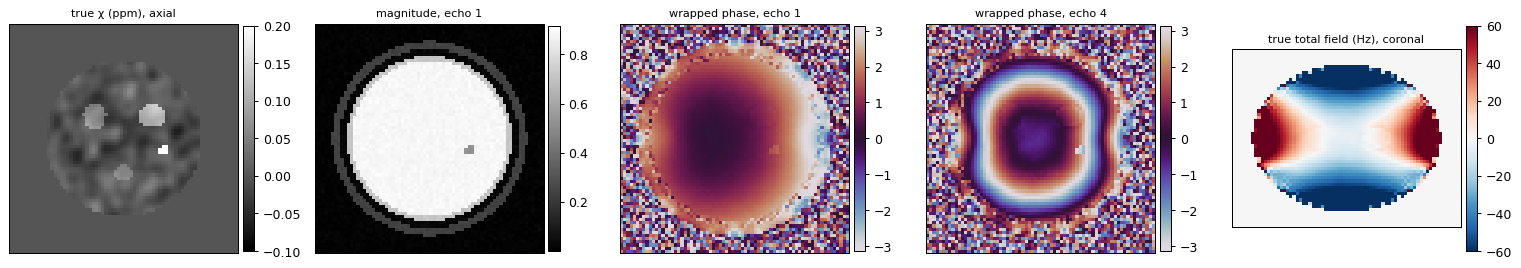

In [2]:
TE = (0.004, 0.008, 0.012, 0.016)      # s
P = ov.tl.qsm_numerical_phantom(shape=(72, 72, 56), voxel_size=(1.0, 1.0, 1.0), b0_tesla=3.0,
                                echo_times=TE, b0_dir=(0.0, 0.0, 1.0), noise=0.01, seed=0)
vs, b0dir, B0 = P["voxel_size"], P["b0_dir"], P["b0_tesla"]
brain = P["brain_mask"]
print("phase / magnitude:", P["phase"].shape, P["phase"].dtype,
      f"phase range [{P['phase'].min():.2f}, {P['phase'].max():.2f}] rad")
print("structures:", {k: v for k, (s, v) in P["structures"].items()})
print(f"brain voxels: {brain.sum()},  Hz per ppm at {B0} T: {GAMMA_BAR * B0:.1f}")

zc, yc = 28, 43        # axial slice through the centre, coronal slice through nuclei a/b
fig, axs = plt.subplots(1, 5, figsize=(17, 3.4))
ax_img(axs[0], P["chi"][:, :, zc], "true χ (ppm), axial", "gray", -0.1, 0.2)
ax_img(axs[1], P["magnitude"][0][:, :, zc], "magnitude, echo 1")
ax_img(axs[2], P["phase"][0][:, :, zc], "wrapped phase, echo 1", "twilight", -np.pi, np.pi)
ax_img(axs[3], P["phase"][3][:, :, zc], "wrapped phase, echo 4", "twilight", -np.pi, np.pi)
ax_img(axs[4], P["field_hz"][:, yc, :], "true total field (Hz), coronal", "RdBu_r", -60, 60)
plt.tight_layout(); plt.show()

The wrapped phase is dominated by the background field and the phase offset. The four echoes
show more and more $2\pi$ wraps as $TE$ grows, and the nuclei are barely visible. The coronal
total field (B0 points up in that panel) is shaped by the air cavities below the brain.

## 2. The dipole kernel and the forward model

`qsm_dipole_kernel(shape, voxel_size, b0_dir)` returns $D(\mathbf k)$ on the unshifted FFT
grid. `qsm_forward_field(chi, ...)` applies it with zero padding (`pad_mm`) so that the
periodic FFT does not wrap the field of one side of the volume onto the other.

D(0)=0.000  D(k || B0)=-0.667  D(k ⟂ B0)=0.333
fraction of k-space with |D| < 0.1 (ill-conditioned): 24.1%
sphere: field on B0 axis at r=12 mm +0.0827 ppm, in the equatorial plane -0.0414 ppm (theory: +2/3·(R/r)^3 = +0.0833, −1/3·(R/r)^3 = -0.0417); inside -0.0000


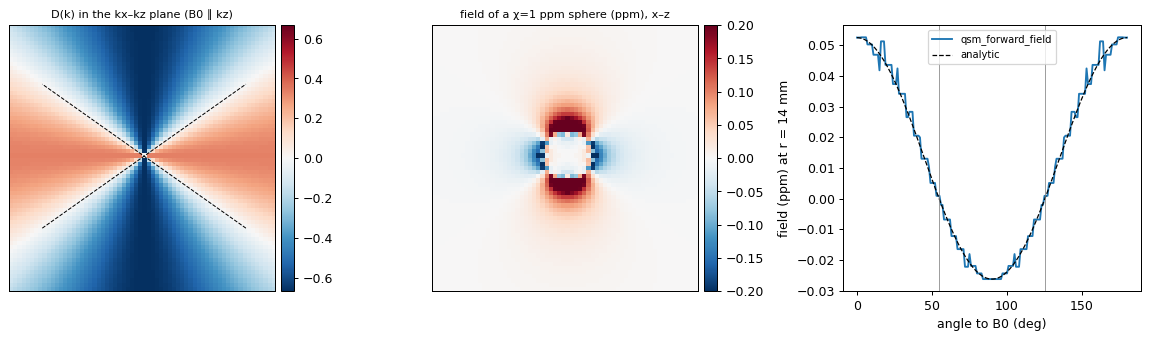

In [3]:
D = ov.tl.qsm_dipole_kernel((64, 64, 64), (1, 1, 1), b0_dir=(0, 0, 1))
Ds = np.fft.fftshift(D)
print(f"D(0)={D[0, 0, 0]:.3f}  D(k || B0)={D[0, 0, 1]:.3f}  D(k ⟂ B0)={D[1, 0, 0]:.3f}")
small = np.mean(np.abs(D) < 0.1)
print(f"fraction of k-space with |D| < 0.1 (ill-conditioned): {small:.1%}")

# field of a uniformly magnetised sphere (radius 6 mm, chi = 1 ppm) in a 64^3 grid
n = 64
g = np.meshgrid(*[np.arange(n) - n / 2] * 3, indexing="ij")
sphere = ((g[0] ** 2 + g[1] ** 2 + g[2] ** 2) <= 36).astype(np.float32)
f_sph = ov.tl.qsm_forward_field(sphere, (1, 1, 1), (0, 0, 1), pad_mm=32)
c = n // 2
print(f"sphere: field on B0 axis at r=12 mm {f_sph[c, c, c + 12]:+.4f} ppm, "
      f"in the equatorial plane {f_sph[c + 12, c, c]:+.4f} ppm (theory: +2/3·(R/r)^3 = {2/3*(6/12)**3:+.4f}, "
      f"−1/3·(R/r)^3 = {-1/3*(6/12)**3:+.4f}); inside {f_sph[c, c, c]:+.4f}")

fig, axs = plt.subplots(1, 3, figsize=(13, 3.8))
ax_img(axs[0], Ds[:, 32, :], "D(k) in the kx–kz plane (B0 ∥ kz)", "RdBu_r", -2/3, 2/3)
ang = np.deg2rad(54.7356)
for s in (+1, -1):
    axs[0].plot([32 - 30 * np.sin(ang) * s, 32 + 30 * np.sin(ang) * s],
                [32 - 30 * np.cos(ang), 32 + 30 * np.cos(ang)], "k--", lw=0.8)
ax_img(axs[1], f_sph[:, c, :], "field of a χ=1 ppm sphere (ppm), x–z", "RdBu_r", -0.2, 0.2)
th = np.linspace(0, np.pi, 181)
r = 14
axs[2].plot(np.rad2deg(th), [f_sph[c + int(round(r * np.sin(t))), c, c + int(round(r * np.cos(t)))]
                              for t in th], label="qsm_forward_field")
axs[2].plot(np.rad2deg(th), (6 / r) ** 3 * (3 * np.cos(th) ** 2 - 1) / 3, "k--", lw=1, label="analytic")
axs[2].axvline(54.7, color="gray", lw=0.6); axs[2].axvline(125.3, color="gray", lw=0.6)
axs[2].set_xlabel("angle to B0 (deg)"); axs[2].set_ylabel("field (ppm) at r = 14 mm"); axs[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

The dashed lines in the first panel mark the magic-angle cone where $D=0$. About a quarter of
k-space has $|D|<0.1$. The field outside the sphere follows the analytic dipole
$\tfrac13(R/r)^3(3\cos^2\theta-1)$. It is positive along $B_0$, negative and half as large
across it, and zero at 54.7°. Inside a uniform sphere the field is ≈0, as the Lorentz-sphere
correction built into $D$ predicts. Applied to a χ map, the forward model is what a pipeline
has to invert. It is also the tool for checking a result, because a good χ should reproduce
the measured local field.

## 3. Brain mask from the magnitude

`qsm_brain_mask` thresholds the first-echo magnitude (half the Otsu level by default). It
then cuts thin connections to the scalp with a morphological opening, keeps the largest
component, closes and fills holes. Last, it erodes the surface when the image still contains
scalp signal (`erode_mm='auto'`). The partial-volume rim between brain, CSF and skull has
unreliable phase. The phantom keeps its scalp (it is not skull-stripped), so the automatic
rule erodes 3 mm.

In [4]:
mask, info = ov.tl.qsm_brain_mask(P["magnitude"], voxel_size=vs, return_info=True)
dice = 2 * (mask & brain).sum() / (mask.sum() + brain.sum())
print(info)
print(f"mask voxels {mask.sum()}, true brain {brain.sum()}, inside the true brain: {(mask & brain).sum() / mask.sum():.1%} of the mask, Dice {dice:.3f}")
mask0 = ov.tl.qsm_brain_mask(P["magnitude"], voxel_size=vs, erode_mm=0)
print(f"without erosion: {mask0.sum()} voxels, outside the true brain: {(mask0 & ~brain).sum()}")

{'threshold': 0.13705512881278992, 'signal_outside_ratio': 0.3782178217821782, 'skull_stripped': False, 'erode_mm': 3.0}
mask voxels 38192, true brain 47712, inside the true brain: 100.0% of the mask, Dice 0.889


without erosion: 56560 voxels, outside the true brain: 8848


The eroded mask lies entirely inside the true brain (Dice ≈ 0.89, because the 3 mm rim is
missing). Without erosion, the mask follows the bright CSF layer outside the brain. In this
tutorial the **true brain mask** is used for the step-by-step analysis, so that each step is
judged on its own. `qsm_reconstruct` (Section 8) computes its own mask.

## 4. Phase unwrapping

The measured phase is $\phi_n = \mathcal W(\phi_0 + 2\pi\Delta f\,TE_n)$, where $\mathcal W$
wraps into $[-\pi,\pi)$. Unwrapping has to add the correct integer multiple of $2\pi$ to
every voxel. `qsm_unwrap_phase` offers two methods.

* `'quality'`: reliability-sorted path following (Herráez 2002, via scikit-image). Voxel pairs
  are joined in order of phase smoothness, and each voxel gets an **exact** multiple of
  $2\pi$.
* `'laplacian'`: solves $\nabla^2\phi = \cos\phi\,\nabla^2\sin\phi - \sin\phi\,\nabla^2\cos\phi$
  with FFTs (Schofield & Zhu 2003). It is robust to noise but only approximate. The result is
  snapped to the nearest $2\pi$-consistent value, and wherever the approximation is off by
  more than π the snap picks the wrong cycle.

The true unwrapped phase of the phantom is $\phi_0 + 2\pi\Delta f\,TE$. We count the voxels
whose unwrapped value is off by a whole cycle (after removing one global multiple of $2\pi$,
which is harmless).

quality   echo 1: voxels with a 2π error  0.03%
quality   echo 4: voxels with a 2π error  0.38%


laplacian echo 1: voxels with a 2π error  0.14%


laplacian echo 4: voxels with a 2π error 13.99%


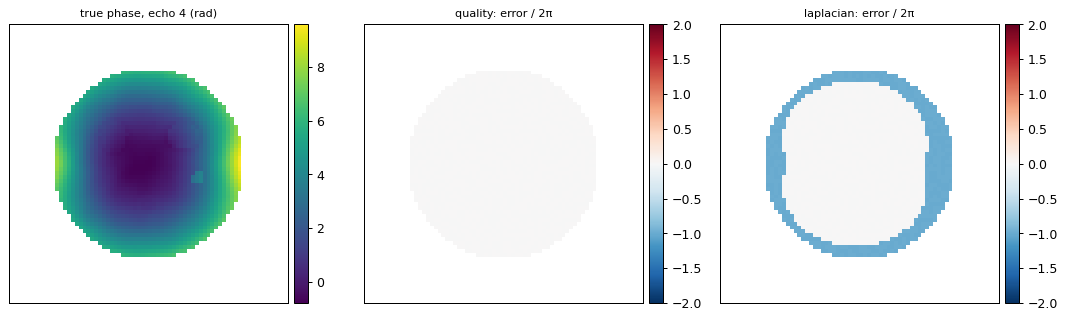

In [5]:
true_phase = [P["phase_offset"] + 2 * np.pi * P["field_hz"] * t for t in TE]
unw = {}
for meth in ("quality", "laplacian"):
    for e in (0, 3):
        u = ov.tl.qsm_unwrap_phase(P["phase"][e], brain, method=meth, voxel_size=vs)
        d = (u - true_phase[e])
        d -= 2 * np.pi * np.round(np.median(d[brain]) / (2 * np.pi))
        unw[meth, e] = d
        print(f"{meth:9s} echo {e + 1}: voxels with a 2π error {np.mean(np.abs(d[brain]) > np.pi):6.2%}")

fig, axs = plt.subplots(1, 3, figsize=(12, 3.5))
ax_img(axs[0], np.where(brain, true_phase[3], np.nan)[:, :, zc], "true phase, echo 4 (rad)", "viridis")
ax_img(axs[1], np.where(brain, unw["quality", 3] / (2 * np.pi), np.nan)[:, :, zc],
       "quality: error / 2π", "RdBu_r", -2, 2)
ax_img(axs[2], np.where(brain, unw["laplacian", 3] / (2 * np.pi), np.nan)[:, :, zc],
       "laplacian: error / 2π", "RdBu_r", -2, 2)
plt.tight_layout(); plt.show()

At the first echo both methods are almost exact. At the fourth echo the phase is steep around
the strong inclusion, the vessel and the air cavities. Laplacian unwrapping then puts **whole-cycle
errors** into a large fraction of the brain (about 14 % here), while quality-guided unwrapping
stays below 0.5 %. A $2\pi$ error at $TE=16$ ms is a 62 Hz (0.5 ppm at 3 T) field error,
far larger than the local tissue field. This is the first pitfall: a smooth-looking
Laplacian result is not proof of correct unwrapping. Check it against the echo-time
linearity of the phase, as the next step does.

## 5. Multi-echo field estimation and the phase offset

With several echoes, the field is the slope of phase vs $TE$. `qsm_multi_echo_field` does the
following.

1. Estimates the TE-independent offset $\phi_0$ by MCPC-3D-S (Eckstein 2018). The difference
   between echoes 2 and 1 gives $2\pi\Delta f(TE_2-TE_1)$ with the offset cancelled. That
   difference is unwrapped and extrapolated back to $TE=0$. The remainder is smoothed inside
   the mask, giving $\phi_0$.
2. Unwraps every offset-corrected echo in 3D and aligns the echoes by whole cycles to the
   echo-difference frequency. Per voxel, it also tries a *temporal* unwrapping (cycle counts
   from that frequency) and keeps whichever fits better (`echo_unwrap='auto'`).
3. Fits $\phi_n = 2\pi\Delta f\,TE_n$ through the origin by least squares weighted with
   $|S_n|^2$. It returns $\Delta f$ (Hz), the RMS fit residual, and a *reliable mask* of
   voxels with residual < `max_residual`.

Without offset removal, a line through the origin cannot fit $\phi_0 + 2\pi\Delta f\,TE$.
The offset leaks into the field as roughly $\phi_0/(2\pi\,\overline{TE})$.

MCPC-3D-S offset removal  : field error rms  3.80 Hz, p99 |err|  0.59 Hz, median fit residual 0.011 rad, reliable voxels 47680
no offset removal         : field error rms  7.29 Hz, p99 |err| 11.56 Hz, median fit residual 0.195 rad, reliable voxels 44733
estimated phase offset vs truth: rms 0.011 rad (true offset spans 1.57 rad)
voxels with |error| > 2 Hz: 11 (0.02% of the brain); depth below the mask surface [1.] voxels; error [249. 250. 250. 250. 250. 250. 250. 250. 250. 250. 251.] Hz (1/TE1 = 250 Hz); their fit residual 0.022 rad


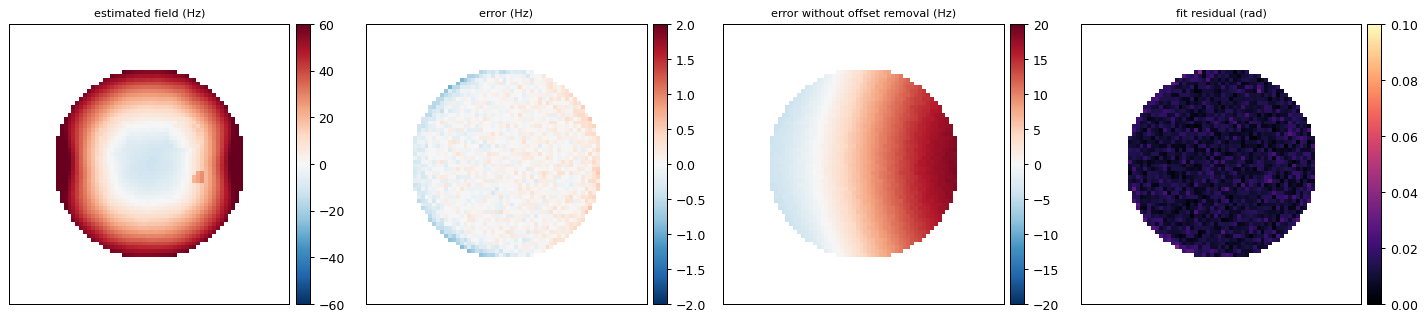

In [6]:
fe = ov.tl.qsm_multi_echo_field(P["phase"], P["magnitude"], P["echo_times"], brain, voxel_size=vs)
fe_nooff = ov.tl.qsm_multi_echo_field(P["phase"], P["magnitude"], P["echo_times"], brain,
                                      voxel_size=vs, remove_offset=False, return_unwrapped=False)
for lab, r in (("MCPC-3D-S offset removal", fe), ("no offset removal", fe_nooff)):
    err = (r["field_hz"] - P["field_hz"])[brain]
    err -= np.median(err)
    print(f"{lab:26s}: field error rms {np.sqrt(np.mean(err ** 2)):5.2f} Hz, "
          f"p99 |err| {np.percentile(np.abs(err), 99):5.2f} Hz, median fit residual "
          f"{np.median(r['residual'][brain]):.3f} rad, reliable voxels {r['reliable_mask'].sum()}")
off_err = np.angle(np.exp(1j * (fe["phase_offset"] - P["phase_offset"])))[brain]
print(f"estimated phase offset vs truth: rms {np.sqrt(np.mean((off_err - np.median(off_err)) ** 2)):.3f} rad "
      f"(true offset spans {np.ptp(P['phase_offset'][brain]):.2f} rad)")
from scipy import ndimage as ndi
err_map = np.abs(fe["field_hz"] - P["field_hz"] - np.median((fe["field_hz"] - P["field_hz"])[brain]))
depth = ndi.distance_transform_edt(brain)
bad = brain & (err_map > 2)
print(f"voxels with |error| > 2 Hz: {bad.sum()} ({bad.sum() / brain.sum():.2%} of the brain); "
      f"depth below the mask surface {np.unique(depth[bad])} voxels; error {np.round(np.unique(err_map[bad]))} Hz "
      f"(1/TE1 = {1 / TE[0]:.0f} Hz); their fit residual {fe['residual'][bad].max():.3f} rad")

fig, axs = plt.subplots(1, 4, figsize=(16, 3.5))
ax_img(axs[0], np.where(brain, fe["field_hz"], np.nan)[:, :, zc], "estimated field (Hz)", "RdBu_r", -60, 60)
ax_img(axs[1], np.where(brain, fe["field_hz"] - P["field_hz"], np.nan)[:, :, zc], "error (Hz)", "RdBu_r", -2, 2)
ax_img(axs[2], np.where(brain, fe_nooff["field_hz"] - P["field_hz"], np.nan)[:, :, zc],
       "error without offset removal (Hz)", "RdBu_r", -20, 20)
ax_img(axs[3], np.where(brain, fe["residual"], np.nan)[:, :, zc], "fit residual (rad)", "magma", 0, 0.1)
plt.tight_layout(); plt.show()

With MCPC-3D-S the field error is below 1 Hz in 99 % of the brain, and the estimated offset
matches the true one to 0.01 rad. The larger rms comes from a handful of voxels (0.02 %) on
the outermost layer of the mask, next to the ear-like air cavities. Each of them is off by
exactly $1/TE_1$ = 250 Hz, a whole cycle at every echo at once. Such an error still fits a
straight line through the origin, so its fit residual is as small as anywhere else. The
residual-based reliability mask cannot catch it. The mask erosion in `qsm_brain_mask` and
the boundary erosion of V-SHARP remove exactly this outer layer. Without offset removal, the smooth $\phi_0$ appears as an error of ±10–20 Hz
(0.1 ppm). That is as large as the deep-grey-matter contrast, and it cannot be removed later
because it is not a dipole field. The fit residual is ≈0.01 rad (noise) everywhere except at
such pathological voxels. This is why the residual makes a good reliability mask.

## 6. Background field removal

The total field is about 25 times larger (sd 0.27 ppm) than the local field of the brain
tissue (sd 0.011 ppm). Background removal separates the two. It uses the fact that the
background field is harmonic inside the mask.

* **SHARP / V-SHARP**: a harmonic function equals its own spherical mean (mean-value
  property). Then $f - S_r * f$ ($S_r$ the normalised sphere of radius $r$) contains only the
  local field. Deconvolving $(1 - S_r)$ with a truncation threshold recovers it.
  SHARP uses one radius. V-SHARP uses large radii in the interior and shrinks them towards
  the boundary, which loses fewer edge voxels. Both erode the mask by the smallest radius.
* **PDF** (projection onto dipole fields): fits the field as the dipole field of
  sources outside the mask (conjugate gradient) and subtracts it. It keeps the whole
  mask but needs $\hat{\mathbf b}$.

Ground truth: the local field is the forward field of the brain's own χ,
`qsm_forward_field(chi * brain)`, computed with the same padding the phantom used.

sd inside the brain: total field 0.2697 ppm, true local field 0.0111 ppm


vsharp:   0.3 s, local mask  37320 voxels, NRMSE vs true local field  39.2 %
sharp :   0.1 s, local mask  18880 voxels, NRMSE vs true local field  10.7 %


pdf   :  24.5 s, local mask  47712 voxels, NRMSE vs true local field  49.3 %
on the common (interior) mask: {'vsharp': 13.9, 'sharp': 10.7, 'pdf': 13.9}


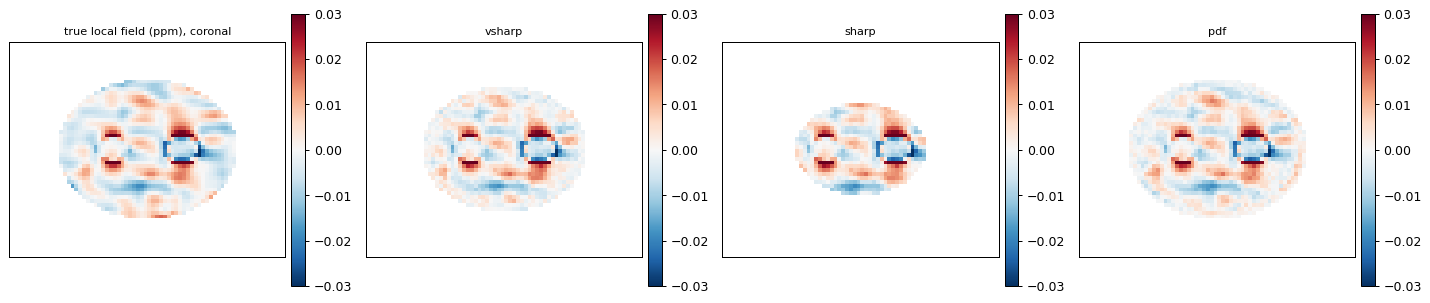

In [7]:
f_ppm = fe["field_hz"] / (GAMMA_BAR * B0)                     # Hz -> ppm of B0
true_local = ov.tl.qsm_forward_field(np.where(brain, P["chi"], 0), vs, b0dir, pad_mm=18.0)
print(f"sd inside the brain: total field {f_ppm[brain].std():.4f} ppm, true local field {true_local[brain].std():.4f} ppm")
bg = {}
for meth in ("vsharp", "sharp", "pdf"):
    t = time.time()
    loc, lm = ov.tl.qsm_background_removal(f_ppm, brain, vs, method=meth, b0_dir=b0dir)
    bg[meth] = (loc, lm)
    print(f"{meth:6s}: {time.time() - t:5.1f} s, local mask {lm.sum():6d} voxels, "
          f"NRMSE vs true local field {nrmse(loc, true_local, lm):5.1f} %")
common = bg["vsharp"][1] & bg["sharp"][1] & bg["pdf"][1]
print("on the common (interior) mask:",
      {k: round(nrmse(v[0], true_local, common), 1) for k, v in bg.items()})

fig, axs = plt.subplots(1, 4, figsize=(16, 3.5))
ax_img(axs[0], np.where(brain, true_local, np.nan)[:, yc, :], "true local field (ppm), coronal", "RdBu_r", -0.03, 0.03)
for a, k in zip(axs[1:], ("vsharp", "sharp", "pdf")):
    loc, lm = bg[k]
    ax_img(a, np.where(lm, loc, np.nan)[:, yc, :], f"{k}", "RdBu_r", -0.03, 0.03)
plt.tight_layout(); plt.show()

All three methods suppress the background by more than an order of magnitude, and the dipole
patterns of the nuclei and the vessel become visible. The NRMSE on each method's own mask
reflects how far it reaches towards the boundary. SHARP (one 6 mm sphere) is the most
accurate but keeps only about half of the brain. V-SHARP keeps most of it, at the cost of
larger errors in the boundary layer handled with small spheres. PDF keeps every voxel but
leaves the most residual background next to the strongest external sources. On the common
interior mask the differences shrink. The choice of method is mostly a choice of how much
boundary to keep. V-SHARP is the default.

## 7. Dipole inversion: an ill-posed problem

`qsm_dipole_inversion` solves $\phi_L = D * \chi$ for $\chi$ (field and χ in ppm).

* **TKD** (truncated k-space division): $\chi = \mathcal F^{-1}[\phi_L/D]$ where
  $|D| > \delta$, and 0 elsewhere. It is fast, but the cone is simply zeroed, which
  underestimates χ and leaves streaks.
* **Tikhonov**: $\min_\chi \|D\chi - \phi_L\|^2 + \lambda\|\Gamma\chi\|^2$, in closed form
  $\chi = \mathcal F^{-1}[D\phi_L/(D^2 + \lambda|\Gamma|^2)]$ with $\Gamma = I$ (identity) or
  the gradient. The penalty shrinks every k-component, so the whole map is **biased
  towards 0**.
* **TV** (ADMM): $\min_\chi \|D\chi - \phi_L\|^2 + \lambda\|\nabla\chi\|_1$. The
  sparse-gradient prior fills the cone with piecewise-smooth structure and keeps the contrast
  of uniform regions close to 1:1. The default is λ = 3·10⁻⁴ for fields in ppm.

We invert the V-SHARP local field. Two measures are compared with the truth: NRMSE inside
the local mask, and the **slope** of reconstructed vs true mean χ over the phantom's
structures (1 = unbiased).

tv       :  1.32 s, NRMSE  47.9 %, ROI slope 0.96
tikhonov :  0.02 s, NRMSE  52.9 %, ROI slope 0.72
tkd      :  0.03 s, NRMSE  55.5 %, ROI slope 0.70

ROI means (ppm):  structure            true     tv   tikhonov   tkd
   nucleus_a            +0.120  +0.086  +0.070  +0.067   (220 voxels)
   nucleus_b            +0.070  +0.047  +0.041  +0.041   (184 voxels)
   nucleus_c            +0.040  +0.044  +0.040  +0.037   (180 voxels)
   nucleus_d            -0.030  -0.026  -0.023  -0.020   (80 voxels)
   vessel               +0.300  +0.260  +0.241  +0.264   (224 voxels)
   negative_inclusion   -1.500  -1.450  -1.071  -1.032   (8 voxels)


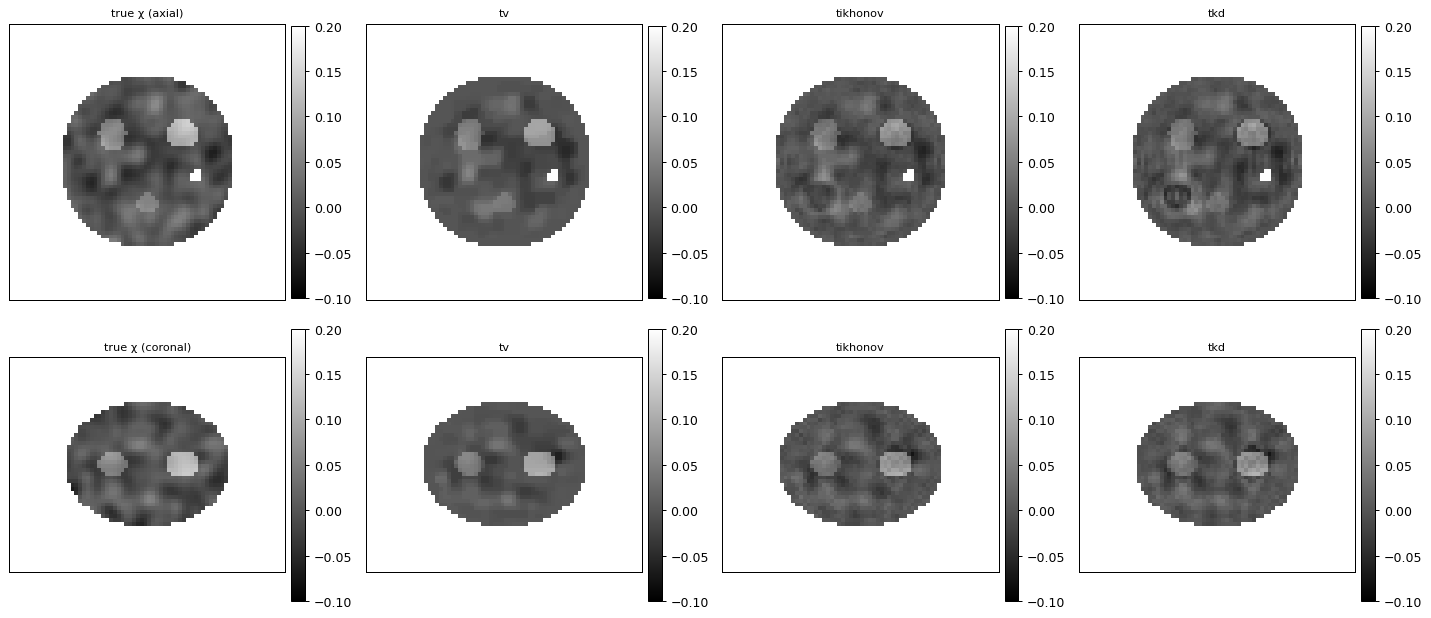

In [8]:
loc, lm = bg["vsharp"]
inv = {}
for meth, kw in (("tv", {}), ("tikhonov", {}), ("tkd", {})):
    t = time.time()
    inv[meth] = ov.tl.qsm_dipole_inversion(loc, lm, vs, b0dir, method=meth, **kw)
    print(f"{meth:9s}: {time.time() - t:5.2f} s, NRMSE {nrmse(inv[meth], P['chi'], lm):5.1f} %, "
          f"ROI slope {roi_slope(inv[meth], P, lm):.2f}")
print("\nROI means (ppm):  structure            true     tv   tikhonov   tkd")
for (name, v, ptv, nv), (_, _, ptk, _), (_, _, pkd, _) in zip(roi_table(inv["tv"], P, lm),
                                                              roi_table(inv["tikhonov"], P, lm),
                                                              roi_table(inv["tkd"], P, lm)):
    print(f"   {name:20s} {v:+6.3f}  {ptv:+6.3f}  {ptk:+6.3f}  {pkd:+6.3f}   ({nv} voxels)")

fig, axs = plt.subplots(2, 4, figsize=(16, 7))
for row, (sl, lab) in enumerate((((slice(None), slice(None), zc), "axial"), ((slice(None), yc, slice(None)), "coronal"))):
    ax_img(axs[row, 0], np.where(lm, P["chi"], np.nan)[sl], f"true χ ({lab})", "gray", -0.1, 0.2)
    for a, k in zip(axs[row, 1:], ("tv", "tikhonov", "tkd")):
        ax_img(a, np.where(lm, inv[k], np.nan)[sl], k, "gray", -0.1, 0.2)
plt.tight_layout(); plt.show()

TV recovers the structure means with a slope close to 1 and the lowest NRMSE. Tikhonov
(identity, λ = 10⁻²) and TKD give smoother but **underestimated** maps, with slopes around 0.7.
In the coronal view (B0 vertical), TKD and Tikhonov show the faint streaks along the
magic-angle directions that come from the missing cone. An NRMSE of 40–50 % looks large.
It is dominated by the 0.02 ppm texture and the −1.5 ppm inclusion, which no method
reproduces voxel by voxel. The ROI means, which are what QSM studies report, agree far
better.

## 8. The whole chain in one call, and a dipole-consistency check

`qsm_reconstruct` runs mask → multi-echo field (with residual-based mask refinement) →
background removal → Hz→ppm with $\bar\gamma B_0$ → inversion. It returns χ, every
intermediate, and a QC `summary`. The `dipole_inconsistency` entry is
$\|D*\hat\chi - \phi_L\| / \|\phi_L\|$, the part of the local field that the final map does
not explain. It needs no ground truth, so it can also be checked on real data.

qsm_reconstruct: 2.3 s
  n_echoes: 4
  echo_times_s: [0.004, 0.008, 0.012, 0.016]
  b0_tesla: 3.0
  b0_dir: (0.0, 0.0, 1.0)
  voxel_size: (1.0, 1.0, 1.0)
  mask_voxels: 38192
  mask_info: {'threshold': 0.13705512881278992, 'signal_outside_ratio': 0.3782178217821782, 'skull_stripped': False, 'erode_mm': 3.0}
  reliable_voxels: 38192
  local_voxels: 29216
  residual_p50_p99: [0.01097352895885706, 0.02575800457969304]
  field_hz_p1_p50_p99: [-66.73365837097168, -1.077395260334015, 62.97196804046616]
  local_ppm_p1_p99: [-0.018977107666432857, 0.029886312130838064]
  chi_ppm_p1_p50_p99: [-0.03973473459482193, -0.0003859168791677803, 0.0845948103815317]
  dipole_inconsistency: 0.19285470247268677
  background: vsharp
  inversion: tv

NRMSE vs true χ: 43.9 %,  ROI slope 0.94
   nucleus_a            true +0.120  reconstructed +0.082  (220 voxels in the local mask)
   nucleus_b            true +0.070  reconstructed +0.047  (184 voxels in the local mask)
   nucleus_c            true +0.040  rec

background='pdf': NRMSE 48.8 %, slope 0.90, local voxels 38192, inconsistency 0.234


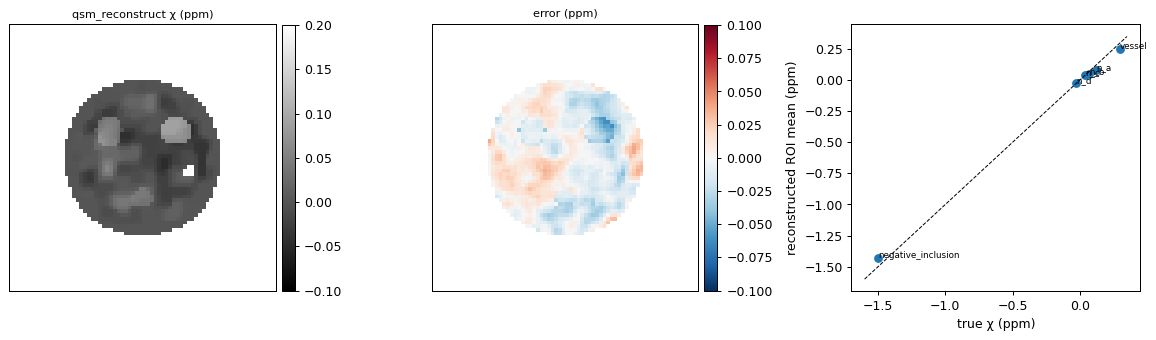

In [9]:
t = time.time()
res = ov.tl.qsm_reconstruct(P["phase"], P["magnitude"], P["echo_times"], b0_tesla=B0,
                            voxel_size=vs, b0_dir=b0dir)
print(f"qsm_reconstruct: {time.time() - t:.1f} s")
for k, v in res["summary"].items():
    print(f"  {k}: {v}")
lmr = res["local_mask"]
print(f"\nNRMSE vs true χ: {nrmse(res['chi'], P['chi'], lmr):.1f} %,  ROI slope {roi_slope(res['chi'], P, lmr):.2f}")
for name, v, pm, nv in roi_table(res["chi"], P, lmr):
    print(f"   {name:20s} true {v:+6.3f}  reconstructed {pm:+6.3f}  ({nv} voxels in the local mask)")

res_pdf = ov.tl.qsm_reconstruct(P["phase"], P["magnitude"], P["echo_times"], B0, vs, b0_dir=b0dir,
                                background="pdf")
print(f"background='pdf': NRMSE {nrmse(res_pdf['chi'], P['chi'], res_pdf['local_mask']):.1f} %, "
      f"slope {roi_slope(res_pdf['chi'], P, res_pdf['local_mask']):.2f}, "
      f"local voxels {res_pdf['summary']['local_voxels']}, inconsistency {res_pdf['summary']['dipole_inconsistency']:.3f}")

rows = roi_table(res["chi"], P, lmr)
fig, axs = plt.subplots(1, 3, figsize=(13, 3.8))
ax_img(axs[0], np.where(lmr, res["chi"], np.nan)[:, :, zc], "qsm_reconstruct χ (ppm)", "gray", -0.1, 0.2)
ax_img(axs[1], np.where(lmr, res["chi"] - P["chi"], np.nan)[:, :, zc], "error (ppm)", "RdBu_r", -0.1, 0.1)
tv_ = np.array([r[1] for r in rows]); pv_ = np.array([r[2] for r in rows])
axs[2].plot([-1.6, 0.35], [-1.6, 0.35], "k--", lw=0.8)
axs[2].scatter(tv_, pv_)
for r in rows:
    axs[2].annotate(r[0].replace("nucleus_", "n_"), (r[1], r[2]), fontsize=7)
axs[2].set_xlabel("true χ (ppm)"); axs[2].set_ylabel("reconstructed ROI mean (ppm)")
plt.tight_layout(); plt.show()

The one-call pipeline matches the step-by-step chain (NRMSE ≈ 44 %, ROI slope ≈ 0.94) with
its own eroded mask. The QC summary shows a median fit residual of 0.01 rad (noise level),
and a dipole inconsistency of about 0.2, so the χ map explains about 80 % of the local field
norm. The rest is mostly noise and texture that TV smooths away. The ROI scatter lies close
to the identity line. The most paramagnetic structures (vessel, nucleus a) read 10–30 % low,
the usual partial-volume and regularisation loss for small, high-contrast objects. PDF gives
a similar map on a larger mask (no erosion by the sphere radius). Leave `background`, `inversion` and `lam` at their defaults unless a validated
reason says otherwise.

## 9. Reading and writing data: a BIDS-like round trip

Real multi-echo GRE data usually come as one NIfTI per echo and part (BIDS:
`sub-<label>_echo-<n>_part-{mag,phase}_MEGRE.nii[.gz]`). A JSON sidecar holds `EchoTime`
(s) and `MagneticFieldStrength` (T). `qsm_load_multi_echo(directory)` finds the files by
these entities, sorts them by echo, and rescales integer-coded phase to radians. It reads
echo times, field strength and (if present) `B0_dir` from the sidecars. When `B0_dir` is
absent, it derives B0 from the affine as the scanner z axis in voxel coordinates.
`qsm_save_nifti` writes float32 NIfTI-1 with the given affine. nibabel is used when
installed, otherwise a built-in writer. Here we write the simulated echoes, load them back
and reconstruct from the files.

In [10]:
try:
    import nibabel
    print("nibabel", nibabel.__version__, "(used by qsm_save_nifti / qsm_load_multi_echo)")
except ImportError:
    nibabel = None
    print("nibabel not installed: the built-in NIfTI-1 reader/writer is used")

affine = np.diag(list(vs) + [1.0])
affine[:3, 3] = [-36.0, -36.0, -28.0]          # an arbitrary origin, as scanners write
with tempfile.TemporaryDirectory() as tmp:
    anat = os.path.join(tmp, "sub-01", "anat")
    for e, te in enumerate(TE, start=1):
        for part, arr in (("phase", P["phase"][e - 1]), ("mag", P["magnitude"][e - 1])):
            stem = os.path.join(anat, f"sub-01_echo-{e}_part-{part}_MEGRE")
            ov.tl.qsm_save_nifti(arr, stem + ".nii.gz", affine=affine)
            with open(stem + ".json", "w") as fh:
                json.dump({"EchoTime": te, "MagneticFieldStrength": B0, "EchoNumber": e}, fh)
    print(sorted(os.listdir(anat))[:4], "...", len(os.listdir(anat)), "files")

    d = ov.tl.qsm_load_multi_echo(anat)
    print("loaded:", d["phase"].shape, "TE", d["echo_times"], "B0", d["b0_tesla"], "T, b0_dir", d["b0_dir"],
          "voxel", d["voxel_size"])
    print("max |phase difference| after round trip:", float(np.abs(d["phase"] - P["phase"]).max()),
          " magnitude:", float(np.abs(d["magnitude"] - P["magnitude"]).max()))

    r2 = ov.tl.qsm_reconstruct(d["phase"], d["magnitude"], d["echo_times"], d["b0_tesla"],
                               d["voxel_size"], b0_dir=d["b0_dir"])
    print("χ from files identical to the in-memory run:", np.allclose(r2["chi"], res["chi"], atol=1e-6))
    out = ov.tl.qsm_save_nifti(r2["chi"], os.path.join(tmp, "derivatives", "qsm", "sub-01_Chimap.nii"),
                               affine=d["affine"])
    if nibabel is not None:
        img = nibabel.load(out)
        print("written:", os.path.relpath(out, tmp), img.shape, img.get_data_dtype(),
              "zooms", img.header.get_zooms(), "origin", img.affine[:3, 3])

nibabel 5.3.2 (used by qsm_save_nifti / qsm_load_multi_echo)


['sub-01_echo-1_part-mag_MEGRE.json', 'sub-01_echo-1_part-mag_MEGRE.nii.gz', 'sub-01_echo-1_part-phase_MEGRE.json', 'sub-01_echo-1_part-phase_MEGRE.nii.gz'] ... 16 files
loaded: (4, 72, 72, 56) TE [0.004 0.008 0.012 0.016] B0 3.0 T, b0_dir (0.0, 0.0, 1.0) voxel (1.0, 1.0, 1.0)
max |phase difference| after round trip: 0.0  magnitude: 0.0


χ from files identical to the in-memory run: True
written: derivatives/qsm/sub-01_Chimap.nii (72, 72, 56) float32 zooms (1.0, 1.0, 1.0) origin [-36. -36. -28.]


The round trip is lossless (float32), and the echo times and field strength come from the
sidecars. B0 direction is derived from the affine, which here is axis-aligned, so B0 = voxel
z. The χ map from the files equals the in-memory result and is written with the input
geometry. For oblique acquisitions, B0 in voxel coordinates is not (0, 0, 1). Pass the
loader's `b0_dir` to every step, as above.

## 10. Pitfalls

Section 4 showed whole-cycle errors from Laplacian unwrapping, and Section 5 showed the
phase-offset leak. Three more failure modes follow.

### 10a. Tikhonov regularisation trades streaks for underestimation

A larger λ suppresses streaking but shrinks χ towards zero. A smaller λ restores the
contrast but amplifies noise near the cone. No single λ gives both, which is why the
TV prior is the default.

tikhonov λ= 1e-04: NRMSE   81.3 %, ROI slope 0.94
tikhonov λ= 1e-03: NRMSE   61.5 %, ROI slope 0.88
tikhonov λ= 1e-02: NRMSE   52.9 %, ROI slope 0.72
tikhonov λ= 3e-02: NRMSE   56.7 %, ROI slope 0.57
tikhonov λ= 1e-01: NRMSE   69.0 %, ROI slope 0.37


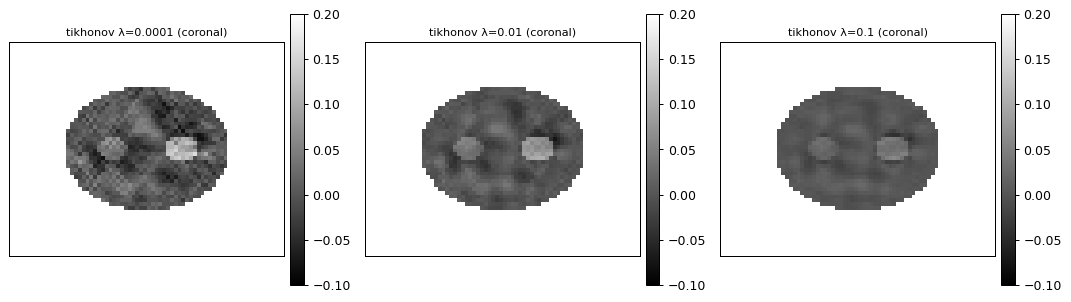

In [11]:
lams = [1e-4, 1e-3, 1e-2, 3e-2, 1e-1]
tik = [(l, ov.tl.qsm_dipole_inversion(loc, lm, vs, b0dir, method="tikhonov", lam=l)) for l in lams]
for l, chi_l in tik:
    print(f"tikhonov λ={l:6.0e}: NRMSE {nrmse(chi_l, P['chi'], lm):6.1f} %, ROI slope {roi_slope(chi_l, P, lm):.2f}")
fig, axs = plt.subplots(1, 3, figsize=(12, 3.6))
for a, (l, chi_l) in zip(axs, [tik[0], tik[2], tik[4]]):
    ax_img(a, np.where(lm, chi_l, np.nan)[:, yc, :], f"tikhonov λ={l:g} (coronal)", "gray", -0.1, 0.2)
plt.tight_layout(); plt.show()

At λ = 10⁻⁴ the contrast is nearly 1:1 (slope ≈ 0.9) but the map is dominated by
noise and streaks, which gives the highest NRMSE. As λ grows, the map gets cleaner and the slope falls
(≈ 0.37 at λ = 0.1), so every structure reads too weak. Tikhonov maps, and TKD maps with
a large threshold, systematically underestimate susceptibility. Values from them should not
be compared with TV-based literature values.

### 10b. Non-harmonic "background" cannot be removed

Background removal can only remove fields that are harmonic inside the mask, i.e. fields
whose sources are outside it. A common mistake when building a test phantom is to add an
arbitrary smooth "shim" field. Then the background step "fails", and one draws wrong
conclusions about the method. Here we add two smooth quadratic fields of the same amplitude
to the total field. One is harmonic, $x^2 - y^2$. The other is not, $x^2 + y^2 + z^2$,
because its Laplacian is $6 \ne 0$. Background removal is linear, so we can follow each
added component through it.

In [12]:
gx, gy, gz = np.meshgrid(*[(np.arange(n_) - (n_ - 1) / 2) * v for n_, v in zip(brain.shape, vs)], indexing="ij")
R = 24.0
added = {"harmonic  x²−y²": (gx ** 2 - gy ** 2) / R ** 2,
         "non-harmonic x²+y²+z²": (gx ** 2 + gy ** 2 + gz ** 2) / R ** 2}
for name, h in added.items():
    h = (0.05 * h / np.abs(h[brain]).max()).astype(np.float32)      # 0.05 ppm peak = 6.4 Hz at 3 T
    for meth in ("vsharp", "pdf"):
        leak, lmh = ov.tl.qsm_background_removal(np.where(brain, h, 0), brain, vs, method=meth, b0_dir=b0dir)
        lv = leak[lmh] - leak[lmh].mean(); hv = h[lmh] - h[lmh].mean()
        f_bad, lm_bad = ov.tl.qsm_background_removal(f_ppm + np.where(brain, h, 0), brain, vs, method=meth, b0_dir=b0dir)
        chi_bad = ov.tl.qsm_dipole_inversion(f_bad, lm_bad, vs, b0dir)
        print(f"{name:22s} {meth:6s}: left in local field {100 * np.linalg.norm(lv) / np.linalg.norm(hv):5.1f} % "
              f"(= {lv.std():.4f} ppm sd vs local tissue field {true_local[lmh].std():.4f}),  "
              f"χ NRMSE {nrmse(chi_bad, P['chi'], lm_bad):5.1f} % (clean: {nrmse(ov.tl.qsm_dipole_inversion(*bg[meth], vs, b0dir), P['chi'], bg[meth][1]):.1f} %)")

harmonic  x²−y²        vsharp: left in local field   0.0 % (= 0.0000 ppm sd vs local tissue field 0.0122),  χ NRMSE  47.9 % (clean: 47.9 %)


harmonic  x²−y²        pdf   : left in local field   0.1 % (= 0.0000 ppm sd vs local tissue field 0.0111),  χ NRMSE  56.8 % (clean: 56.8 %)


non-harmonic x²+y²+z²  vsharp: left in local field  43.5 % (= 0.0045 ppm sd vs local tissue field 0.0122),  χ NRMSE  53.3 % (clean: 47.9 %)


non-harmonic x²+y²+z²  pdf   : left in local field  79.1 % (= 0.0095 ppm sd vs local tissue field 0.0111),  χ NRMSE  86.6 % (clean: 56.8 %)


Both methods remove the harmonic component completely (0.0–0.1 % left), and the χ map is
unchanged. The non-harmonic component is only partly removed: V-SHARP leaves about 40 % of
it and PDF about 80 %. PDF can only fit dipole fields of outside sources, and for SMV methods
a field with non-zero Laplacian counts as local. The leftover is 40–85 % of the size of the
real tissue field, and the inversion turns it into spurious χ. The χ NRMSE rises from 48 to
53 % (V-SHARP) and from 57 to 87 % (PDF). This is the expected behaviour of a correct
method on an impossible input, not a failure of background removal. To test background
removal on a phantom, put the background *sources* outside the mask and compute their field
with `qsm_forward_field`, as `qsm_numerical_phantom` does. Low-order harmonic polynomials
also work.

### 10c. Tuning λ on a texture-free phantom

Real tissue is not piecewise constant. On a phantom made only of uniform blobs, stronger
smoothing always looks better, because TV with a large λ reproduces flat regions perfectly.
The λ that minimises NRMSE there is too large for real data. `qsm_numerical_phantom` adds
zero-mean texture (`texture=0.02` ppm) for this reason. We compare the λ sweep on the same
phantom with and without texture.

texture 0.02 ppm: NRMSE per λ [43.4 43.9 48.  57.2] -> best λ = 0.0001


texture 0.00 ppm: NRMSE per λ [30.5 28.1 27.2 36.3] -> best λ = 0.001


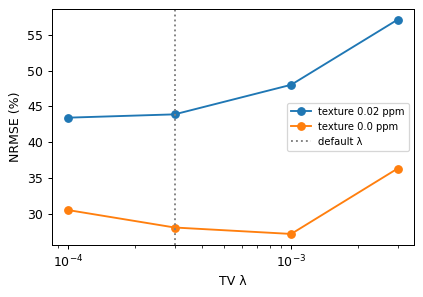

In [13]:
lam_grid = [1e-4, 3e-4, 1e-3, 3e-3]
curves = {}
for tex in (0.02, 0.0):
    Q = P if tex == 0.02 else ov.tl.qsm_numerical_phantom(shape=(72, 72, 56), voxel_size=vs, b0_tesla=B0,
                                                          echo_times=TE, noise=0.01, seed=0, texture=0.0)
    rq = ov.tl.qsm_reconstruct(Q["phase"], Q["magnitude"], Q["echo_times"], B0, vs, b0_dir=b0dir)
    lmq = rq["local_mask"]
    curves[tex] = [nrmse(ov.tl.qsm_dipole_inversion(rq["local_field_ppm"], lmq, vs, b0dir, method="tv", lam=l),
                         Q["chi"], lmq) for l in lam_grid]
    best = lam_grid[int(np.argmin(curves[tex]))]
    print(f"texture {tex:4.2f} ppm: NRMSE per λ {np.round(curves[tex], 1)} -> best λ = {best:g}")
plt.figure(figsize=(4.8, 3.4))
for tex, cv in curves.items():
    plt.semilogx(lam_grid, cv, "o-", label=f"texture {tex} ppm")
plt.axvline(3e-4, color="gray", ls=":", label="default λ")
plt.xlabel("TV λ"); plt.ylabel("NRMSE (%)"); plt.legend(fontsize=8); plt.tight_layout(); plt.show()

Without texture, the NRMSE optimum moves to λ ≈ 10⁻³. With realistic texture it is at
1–3·10⁻⁴, around the default, and λ = 10⁻³ is already clearly worse. A phantom checks that
the *chain* is correct (units, signs, B0 direction, unwrapping, background). Choosing the
regularisation weight from a phantom is only safe when the phantom has realistic
fine-scale structure, and even then it is better to keep the validated default.

In [14]:
print(f"total run time: {time.time() - T0:.0f} s")

total run time: 208 s


## Summary

* Field = $D * \chi$ in k-space. $D$ vanishes on the magic-angle cone, so the inversion needs
  regularisation (`qsm_dipole_kernel`, `qsm_forward_field`).
* Phase must be unwrapped with an exact method (`qsm_unwrap_phase(method='quality')`), and the
  TE-independent offset must be removed before the multi-echo fit (`qsm_multi_echo_field`).
  The fit residual is a ground-truth-free reliability check.
* Harmonic background removal (`qsm_background_removal`) removes fields of sources outside the
  mask and nothing else.
* TV inversion (`qsm_dipole_inversion`, default) keeps ROI contrast close to 1:1. Tikhonov and
  TKD underestimate it.
* `qsm_reconstruct` runs the whole chain with validated defaults. `qsm_load_multi_echo` and
  `qsm_save_nifti` handle BIDS-style NIfTI + JSON input and output.

## References

* Salomir R, de Senneville BD, Moonen CTW. A fast calculation method for magnetic field inhomogeneity due to an arbitrary distribution of bulk susceptibility. *Concepts Magn Reson B* 2003;19B:26–34. doi:10.1002/cmr.b.10083
* Marques JP, Bowtell R. Application of a Fourier-based method for rapid calculation of field inhomogeneity due to spatial variation of magnetic susceptibility. *Concepts Magn Reson B* 2005;25B:65–78. doi:10.1002/cmr.b.20034
* Herráez MA, Burton DR, Lalor MJ, Gdeisat MA. Fast two-dimensional phase-unwrapping algorithm based on sorting by reliability following a noncontinuous path. *Appl Opt* 2002;41:7437–7444. doi:10.1364/AO.41.007437 (3D extension: Abdul-Rahman et al., *Appl Opt* 2007;46:6623.)
* Schofield MA, Zhu Y. Fast phase unwrapping algorithm for interferometric applications. *Opt Lett* 2003;28:1194–1196. doi:10.1364/OL.28.001194
* Eckstein K, Dymerska B, Bachrata B, et al. Computationally efficient combination of multi-channel phase data from multi-echo acquisitions (ASPIRE / MCPC-3D-S). *Magn Reson Med* 2018;79:2996–3006. doi:10.1002/mrm.26963
* Schweser F, Deistung A, Lehr BW, Reichenbach JR. Quantitative imaging of intrinsic magnetic tissue properties using MRI signal phase (SHARP). *NeuroImage* 2011;54:2789–2807. doi:10.1016/j.neuroimage.2010.10.070
* Wu B, Li W, Guidon A, Liu C. Whole brain susceptibility mapping using compressed sensing (V-SHARP). *Magn Reson Med* 2012;67:137–147. doi:10.1002/mrm.23000
* Liu T, Khalidov I, de Rochefort L, et al. A novel background field removal method for MRI using projection onto dipole fields (PDF). *NMR Biomed* 2011;24:1129–1136. doi:10.1002/nbm.1670
* Shmueli K, de Zwart JA, van Gelderen P, et al. Magnetic susceptibility mapping of brain tissue in vivo using MRI phase data (TKD). *Magn Reson Med* 2009;62:1510–1522. doi:10.1002/mrm.22135
* Bilgic B, Fan AP, Polimeni JR, et al. Fast quantitative susceptibility mapping with L1-regularization and automatic parameter selection. *Magn Reson Med* 2014;72:1444–1459. doi:10.1002/mrm.25029
* QSM Consensus Organization Committee. Recommended implementation of quantitative susceptibility mapping for clinical research in the brain: a consensus of the ISMRM electro-magnetic tissue properties study group. *Magn Reson Med* 2024;91:1834–1862. doi:10.1002/mrm.30006